In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.metrics import r2_score, root_mean_squared_error
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

In [3]:
FILE_PATH = 'Housing.csv'
data = pd.read_csv(FILE_PATH)

In [4]:
data.head()

,rownames,price,lotsize,bedrooms,bathrms,stories,driveway,recroom,fullbase,gashw,airco,garagepl,prefarea
0,1,42000,5850.0,3,1,2,yes,no,yes,no,no,1.0,no
1,2,38500,4000.0,2,1,1,yes,no,no,no,no,0.0,no
2,3,49500,3060.0,3,1,1,yes,no,no,no,no,0.0,no
3,4,60500,6650.0,3,1,2,yes,yes,no,no,no,0.0,no
4,5,61000,6360.0,2,1,1,yes,no,no,no,no,0.0,no


In [7]:
data.tail()

,rownames,price,lotsize,bedrooms,bathrms,stories,driveway,recroom,fullbase,gashw,airco,garagepl,prefarea
541,542,91500,4800.0,3,2,4,yes,yes,no,no,yes,0.0,no
542,543,94000,6000.0,3,2,4,yes,no,no,no,yes,0.0,no
543,544,103000,6000.0,3,2,4,yes,yes,no,no,yes,1.0,no
544,545,105000,6000.0,3,2,2,yes,yes,no,no,yes,1.0,no
545,546,105000,6000.0,3,1,2,yes,no,no,no,yes,1.0,no


In [6]:
data.sample(5)

,rownames,price,lotsize,bedrooms,bathrms,stories,driveway,recroom,fullbase,gashw,airco,garagepl,prefarea
535,536,82000,5800.0,3,2,4,yes,no,no,no,yes,0.0,no
437,438,60000,3520.0,3,1,2,yes,no,no,no,no,0.0,yes
489,490,50000,5880.0,2,1,1,yes,no,no,no,no,0.0,no
242,243,70000,4770.0,3,1,1,yes,yes,yes,no,no,0.0,no
259,260,41000,6000.0,2,1,1,yes,no,no,no,no,0.0,no


In [8]:
data.shape

(546, 13)

In [9]:
data.dtypes

rownames      int64
price         int64
lotsize     float64
bedrooms      int64
bathrms       int64
stories       int64
driveway        str
recroom         str
fullbase        str
gashw           str
airco           str
garagepl    float64
prefarea        str
dtype: object

In [10]:
data.isna().sum()

rownames    0
price       0
lotsize     5
bedrooms    0
bathrms     0
stories     0
driveway    2
recroom     2
fullbase    0
gashw       0
airco       5
garagepl    2
prefarea    2
dtype: int64

In [11]:
data.describe()

,rownames,price,lotsize,bedrooms,bathrms,stories,garagepl
count,546.000000,546.000000,541.000000,546.000000,546.000000,546.000000,544.000000
mean,273.500000,68121.597070,5160.611830,2.965201,1.285714,1.807692,0.694853
std,157.760895,26702.670926,2175.141222,0.737388,0.502158,0.868203,0.861864
min,1.000000,25000.000000,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,137.250000,49125.000000,3584.000000,2.000000,1.000000,1.000000,0.000000
50%,273.500000,62000.000000,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,409.750000,82000.000000,6360.000000,3.000000,2.000000,2.000000,1.000000
max,546.000000,190000.000000,16200.000000,6.000000,4.000000,4.000000,3.000000


In [12]:
target_col = 'price'
y = data[target_col].values
X = data.drop(columns = [target_col, 'rownames'])

In [14]:
X.head()

,lotsize,bedrooms,bathrms,stories,driveway,recroom,fullbase,gashw,airco,garagepl,prefarea
0,5850.0,3,1,2,yes,no,yes,no,no,1.0,no
1,4000.0,2,1,1,yes,no,no,no,no,0.0,no
2,3060.0,3,1,1,yes,no,no,no,no,0.0,no
3,6650.0,3,1,2,yes,yes,no,no,no,0.0,no
4,6360.0,2,1,1,yes,no,no,no,no,0.0,no


In [15]:
numeric_features = (X.select_dtypes(include = 'number').columns.tolist())
categorical_features = (X.select_dtypes(exclude=np.number).columns.tolist())

In [16]:
numeric_transformer = Pipeline(
    steps = [
        ('imputer', SimpleImputer(strategy = 'median')),
    ])

categorical_transformer = Pipeline(
    steps = [
        ('imputer', SimpleImputer(strategy = 'most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ]
)

preprocessor = ColumnTransformer(
    transformers = [
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

In [17]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

In [18]:
rf = RandomForestRegressor(random_state = 42, n_estimators = 400, n_jobs = -1)

pipeline = Pipeline(
    [
        ('preprocessor', preprocessor),
        ('rf', rf),
    ]
)

param_grid = {
    'rf__max_depth': [10, 20, 30, None],
    'rf__min_samples_leaf': [1, 2, 5],
    'rf__min_samples_split': [2, 5, 10],
    'rf__max_features': [.8, 'sqrt', 'log2'],
}
cv = KFold(n_splits=5, random_state=42, shuffle=True)
grid_search = GridSearchCV(
    pipeline,
    param_grid,
    cv = cv,
    scoring = 'neg_mean_squared_error',
    n_jobs = -1,
    verbose = 0,
)

grid_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'rf__max_depth': [10, 20, ...], 'rf__max_features': [0.8, 'sqrt', ...], 'rf__min_samples_leaf': [1, 2, ...], 'rf__min_samples_split': [2, 5, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated 

In [19]:
best_model = grid_search.best_estimator_
grid_search.best_params_

{'rf__max_depth': 10,
 'rf__max_features': 0.8,
 'rf__min_samples_leaf': 1,
 'rf__min_samples_split': 2}

In [20]:
def rmse(y_true, y_pred):
    return root_mean_squared_error(y_true, y_pred)

y_pred_test = best_model.predict(X_test)
print(f'''
Best params:{grid_search.best_params_}
RMSE: {rmse(y_test, y_pred_test):.4f}
R2 Score: {r2_score(y_test, y_pred_test):.2f}
''')


Best params:{'rf__max_depth': 10, 'rf__max_features': 0.8, 'rf__min_samples_leaf': 1, 'rf__min_samples_split': 2}
RMSE: 17338.3178
R2 Score: 0.55



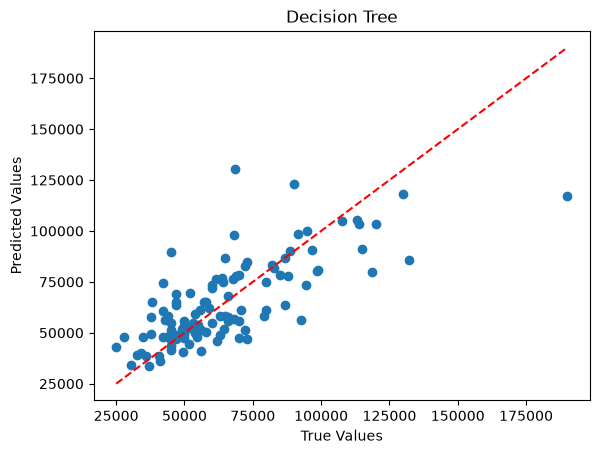

In [21]:
plt.figure()
plt.scatter(y_test, y_pred_test)
plt.xlabel('True Values')
plt.ylabel('Predicted Values')
plt.title('Decision Tree')
low = min(y_test.min(), y_pred_test.min())
high = max(y_test.max(), y_pred_test.max())

plt.plot([low, high], [low, high], 'r--')
plt.show()

In [22]:
oh = None
if categorical_features:
    oh = best_model.named_steps['preprocessor'].transformers_[1][1].named_steps['onehot']
num_names = numeric_features
cat_names = oh.get_feature_names_out(categorical_features).tolist() if oh is not None else []
featured_names  =num_names + cat_names
featured_names

['lotsize',
 'bedrooms',
 'bathrms',
 'stories',
 'garagepl',
 'driveway_no',
 'driveway_yes',
 'recroom_no',
 'recroom_yes',
 'fullbase_no',
 'fullbase_yes',
 'gashw_no',
 'gashw_yes',
 'airco_no',
 'airco_yes',
 'prefarea_no',
 'prefarea_yes']

In [24]:
importances = best_model.named_steps['rf'].feature_importances_
imp_df = (pd.DataFrame({
    'feature': featured_names if len(featured_names) == len(importances) else [f'feature_{i}' for i in range(len(importances))],
    'importance': importances
}).sort_values(by='importance', ascending=False).head(10)
)
imp_df

,feature,importance
0,lotsize,0.444837
2,bathrms,0.130986
4,garagepl,0.078826
3,stories,0.058073
1,bedrooms,0.049901
14,airco_yes,0.048930
13,airco_no,0.047986
9,fullbase_no,0.020436
10,fullbase_yes,0.020124
16,prefarea_yes,0.018255


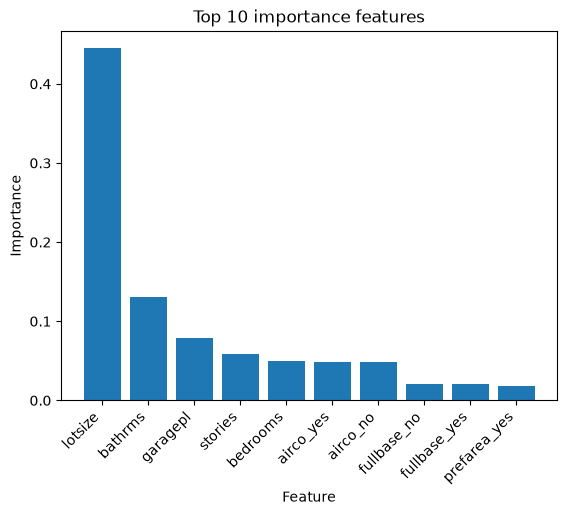

In [25]:
plt.figure()
plt.bar(imp_df['feature'], imp_df['importance'])
plt.xlabel('Feature')
plt.ylabel('Importance')
plt.title('Top 10 importance features')

plt.xticks(rotation=45, ha='right')

plt.show()